# Loss analysis: shear slab weight with and without elasticity

Use the same **14,776 ECTP slabs** as the manuscript to count successful pathways and explain losses. Shear slab weight has four pathways; shear weight with elasticity has 32. Every slab stays in the analysis, including slabs with no successful pathway.

1. Load and check the cohort
2. Calculate both targets and reconcile their results
3. Compare coverage and successful-pathway histograms
4. Compare stepwise losses for both targets
5. Inspect method causes, details, and bottlenecks


In [46]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Works from paper_analysis/, examples/, the repository, or the Snow workspace.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "SnowPyt-MechParams"]
repo_root = next(p for p in candidates if (p / "src/snowpyt_mechparams").is_dir())
sys.path.insert(0, str(repo_root / "src"))
sys.path.insert(0, str(repo_root / "examples"))
sys.path.insert(0, str(repo_root / "paper_analysis"))

from notebook_utils import load_pits, create_ectp_slabs
from loss_analysis_utils import (
    analyze_losses, plot_histogram, comparison_table,
    plot_stepwise_losses, plot_loss_heatmap, plot_method_causes,
)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 2)
warnings.filterwarnings("ignore", message="Using UFloat objects with std_dev==0.*", category=UserWarning)
plt.rcParams.update({"font.size": 10, "figure.dpi": 120})


def show_details(result, parameter, method=None, density_context=None):
    """Readable view; exact numeric bounds and counts remain in result.reasons."""
    frame = result.details(parameter, method, density_context)
    if frame.empty:
        print(f"{parameter}: no recorded failure causes.")
        return
    frame = frame.copy()
    frame["observed"] = [
        f"{low:g}–{high:g}" if pd.notna(low) else examples
        for low, high, examples in zip(
            frame.observed_min, frame.observed_max, frame.observed_examples
        )
    ]
    display(frame[["method", "density_context", "category", "reason", "field",
                   "grain_form", "resolved_grain_form", "slabs", "layers",
                   "observed", "interval", "unit"]])

## 1. Load and check the cohort

Parse the existing CAAML files in sorted filename order, then use `create_ectp_slabs`: one slab per ECTP result, containing the layers above its failure layer. Multiple tests in a pit remain separate slabs. Do not fill in missing slope or other observations.

In [47]:
pits = load_pits(str(repo_root / "examples/data"))
ectp_slabs = create_ectp_slabs(pits)
assert len(pits) == 50_278, "The input dataset differs from the manuscript."
assert len(ectp_slabs) == 14_776, "The ECTP cohort differs from the manuscript."
assert len({slab.slab_id for slab in ectp_slabs}) == len(ectp_slabs)
print(f"Loaded {len(pits):,} pits and {len(ectp_slabs):,} ECTP slabs.")

Loaded 50,278 pits and 14,776 ECTP slabs.


### How to read the loss tables

A pathway succeeds only when all its required layer calculations succeed and its target output is valid: finite shear weight for either target (zero is allowed). For the elasticity target, every layer must also have successful Young’s modulus and Poisson’s-ratio calculations. Calculations propagate input measurement uncertainty only.

**Stepwise losses** use an explicit reporting order to assign each failed slab–pathway attempt to its first unsuccessful step. Each row reconciles `entering = surviving + newly_lost`. The newly lost slabs are partitioned into missing observations only, method validity limits only, both (mixed), or other errors. This order is a reporting convention for a branched dependency graph.

**Method causes** include all identifiable constraints, even on downstream branches. Missing upstream calculated density, E, or Poisson's ratio is labeled **blocked**, not a new missing observation. Density limits are checked only when the selected density method produces a finite value. An observed unsupported grain form is a validity failure; an absent grain form is missing data. Unknown hardness codes are recorded as other errors.

Cause counts overlap: a slab or layer can violate several constraints. `slabs` counts distinct ECTP slabs; `layers` counts distinct original layer observations, including a layer only once when it is shared by several slabs. Shared method steps are also counted once across pathways. `density_context` identifies the selected upstream density method for E and Srivastava; Köchle's Poisson's ratio is independent of density. Context counts must not be added to obtain a unique total.

The diagnostic tables follow the **implemented** domains. They impose no numerical density range on Schöttner and no grain-size range on Kim T6. Observed numeric ranges in the detail tables show the minimum and maximum violating values; validity intervals are in the displayed units. Empty intervals mean no numerical range applies. The complete detail table is available as `result.reasons`; use `show_details` to select a method or density context.

## 2. Calculate both targets

Calculate both analyses before displaying their coverage tables or loss figures. All later sections use these results.

### Shear slab weight

Reporting order: density → thickness / integrated weight → slope / shear weight.


In [48]:
weight = analyze_losses(ectp_slabs, "slab_weight_shear")
expected_weight_coverage = {
    "kim_jamieson_table2": 5_470, "geldsetzer": 4_187,
    "kim_jamieson_table6": 697, "data_flow": 109,
}
actual_weight_coverage = weight.coverage.set_index("density_method").successful_slabs.to_dict()
assert actual_weight_coverage == expected_weight_coverage
print(f"{len(weight.attempts):,} slab–pathway attempts; manuscript coverage reproduced.")


slab_weight_shear:   0%|          | 0/14776 [00:00<?, ?slab/s]

59,104 slab–pathway attempts; manuscript coverage reproduced.


### Shear weight with elasticity

Reporting order: density → thickness + slope / shear weight → Young's modulus → Poisson's ratio. This follows the paper's [shear-weight-with-elasticity attrition figure](../paper/figures/slab_weight_shear_with_elasticity_attrition.png). The methods and their domains are illustrated in [paper_diagrams.ipynb](../examples/paper_diagrams.ipynb).

The target retains the calculated shear weight once **both elasticity parameters succeed on every layer**; elasticity is a coverage requirement and does not change the weight value. No layer depth is required. The last stage also checks the final finite target output; any residual output error is classified as an other error there.

**Measured-density fallback remains removed from the dispatcher.** The explicitly selected direct-measurement pathway remains available. A failed empirical density step blocks density-dependent calculations even when measured density exists. All 32 combinations are recalculated using only input measurement uncertainty.

For Kim T2 → Wautier → Köchle, the paper figure retains **5,907 → 5,470 → 1,901 → 687 slabs** from the starting cohort of 14,776. The following assertion checks that exact sequence.

In [49]:
elastic_weight = analyze_losses(ectp_slabs, "slab_weight_shear_with_elasticity")
assert elastic_weight.n_pathways == 32
assert not elastic_weight.attempts.loc[~elastic_weight.attempts.density_ok, "success"].any()
paper_pathway = "Kim T2 → Wautier → Köchle"
paper_stages = elastic_weight.stages[elastic_weight.stages.pathway == paper_pathway].sort_values("step")
assert paper_stages.surviving.tolist() == [5_907, 5_470, 1_901, 687]
print(f"{len(elastic_weight.attempts):,} attempts; {elastic_weight.attempts.success.sum():,} complete pathways succeeded.")
print(f"{elastic_weight.n_slabs - elastic_weight.histogram.loc[0]:,} slabs have at least one successful elasticity pathway.")


slab_weight_shear_with_elasticity:   0%|          | 0/14776 [00:00<?, ?slab/s]

472,832 attempts; 8,139 complete pathways succeeded.
772 slabs have at least one successful elasticity pathway.


### Reconciliation checks

Both histograms include every starting slab; all pathway-step partitions reconcile with the calculated successes. The detailed missing/validity/blocked counts intentionally overlap and are not summed.

In [50]:
for result in [weight, elastic_weight]:
    assert result.histogram.sum() == 14_776
    assert len(result.attempts) == 14_776 * result.n_pathways
    assert result.stages.newly_lost.sum() + result.attempts.success.sum() == len(result.attempts)
assert len(weight.histogram) == 5 and len(elastic_weight.histogram) == 33
print("Cohort, histogram, pathway coverage, and stepwise-loss checks passed.")

Cohort, histogram, pathway coverage, and stepwise-loss checks passed.


## 3. Compare coverage

The first three count columns describe distinct slabs. Successful attempts and lost-attempt categories count slab–pathway pairs; shear weight with elasticity offers eight times as many pathways as shear weight alone. The loss-category columns assign each attempt to its first unsuccessful step and sum to total failed attempts.


In [51]:
display(comparison_table(weight, elastic_weight).T)


target,slab_weight_shear,slab_weight_shear_with_elasticity
pathways,4,32
zero successful pathways,9241,14004
at least one successful pathway,5535,772
all pathways successful,20,0
successful slab–pathway attempts,10463,8139
lost attempts: missing_only,28261,226100
lost attempts: validity_only,7129,132581
lost attempts: mixed,12063,96508
lost attempts: other,1188,9504


In [52]:
display(weight.coverage[["pathway", "successful_slabs", "coverage_percent"]])
display(elastic_weight.coverage[["pathway", "successful_slabs", "coverage_percent"]])


,pathway,successful_slabs,coverage_percent
0,Kim T2,5470,37.02
1,Geldsetzer,4187,28.34
2,Kim T6,697,4.72
3,Measured,109,0.74


,pathway,successful_slabs,coverage_percent
0,Kim T2 → Schöttner → Köchle,687,4.65
1,Kim T2 → Wautier → Köchle,687,4.65
2,Geldsetzer → Schöttner → Köchle,684,4.63
3,Geldsetzer → Wautier → Köchle,684,4.63
4,Geldsetzer → Köchle → Köchle,677,4.58
5,Kim T2 → Köchle → Köchle,581,3.93
6,Kim T2 → Bergfeld → Köchle,465,3.15
7,Geldsetzer → Bergfeld → Köchle,443,3.00
8,Geldsetzer → Schöttner → Srivastava,418,2.83
9,Geldsetzer → Wautier → Srivastava,418,2.83


### Successful-pathway histograms

Both histograms include every slab, including those with zero successful pathways. Shear slab weight has 0–4 successful pathways per slab; shear weight with elasticity has 0–32.


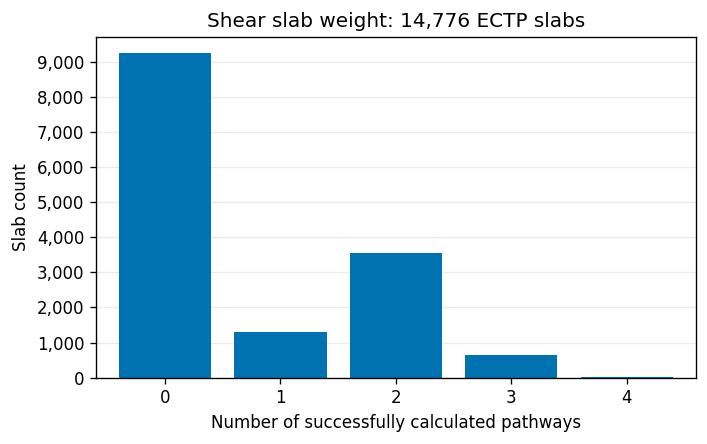

successful_pathways,0,1,2,3,4
slab_count,9241,1304,3554,657,20


In [53]:
plot_histogram(weight)
plt.show()
display(weight.histogram.to_frame().T)

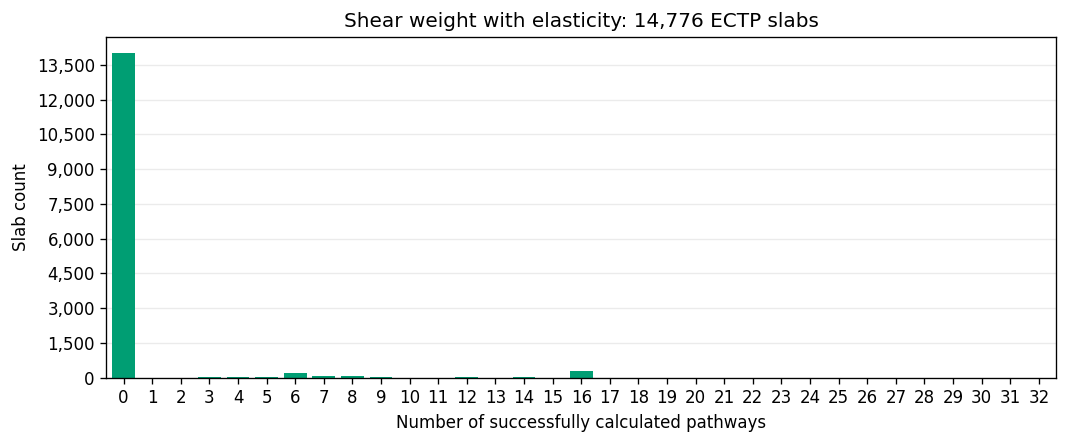

,slab_count
successful_pathways,
0,14004
1,5
2,7
3,17
4,10
5,34
6,187
7,61
8,87


In [54]:
plot_histogram(elastic_weight)
plt.show()
display(elastic_weight.histogram.to_frame())

## 4. Compare stepwise losses

Each pathway starts with all 14,776 slabs. Its final surviving count equals its successful target count.

In both attrition charts, each bar's total is the number entering that step. Green shows survivors; the other colors partition the newly lost slabs. The right-hand labels give exact surviving and lost counts.

Shear slab weight reports density → thickness / integrated weight → slope / shear weight. Shear weight with elasticity combines thickness and slope in the shear-weight step, then checks Young's modulus and Poisson's ratio to match the paper figure. Other errors remain visible rather than being assigned to missing data or a published validity limit.

The two selected-pathway figures appear together below. Change `WEIGHT_PATHWAY` to inspect another density pathway and `ELASTICITY_PATHWAY` to any label in `elastic_weight.coverage` to examine another elasticity combination. The default elasticity pathway reproduces the paper's surviving counts and adds reasons for newly lost slabs.


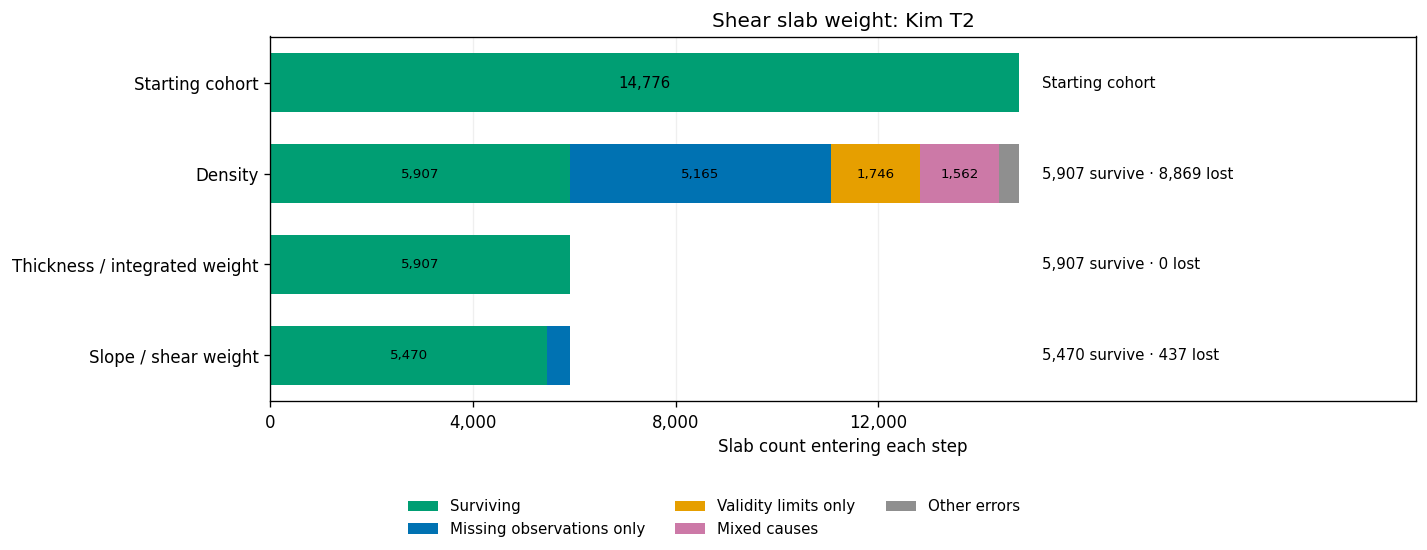

In [55]:
WEIGHT_PATHWAY = "Kim T2"  # Measured, Geldsetzer, Kim T2, or Kim T6
plot_stepwise_losses(weight, WEIGHT_PATHWAY)
plt.show()

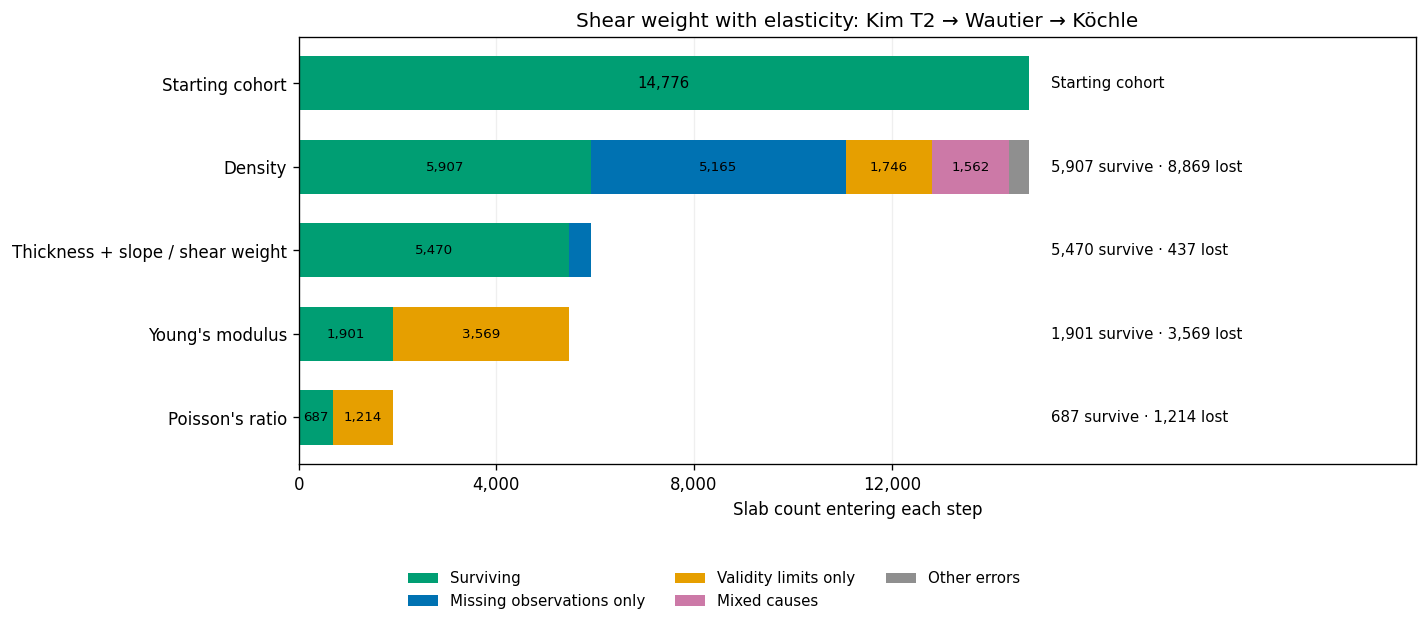

In [56]:
ELASTICITY_PATHWAY = "Kim T2 → Wautier → Köchle"
plot_stepwise_losses(elastic_weight, ELASTICITY_PATHWAY)
plt.show()

### Stepwise loss tables

The tables in `weight.stages` and `elastic_weight.stages` contain all reporting steps for every pathway. Uncomment the displays below to inspect their exact counts.


In [57]:
# display(weight.stages)

In [58]:
#display(elastic_weight.stages)

### Compare stepwise losses across pathways

The heatmaps for both targets appear together below. Each cell shows the percentage of the **original 14,776 slabs** newly lost at that step. Rows are pathways; columns are requirements. Elasticity panels are grouped by density method, with E → Poisson's-ratio combinations as rows. All panels use the same 0–100% color scale. Values below 0.1% are marked `<0.1`; a zero means no slabs were newly lost.


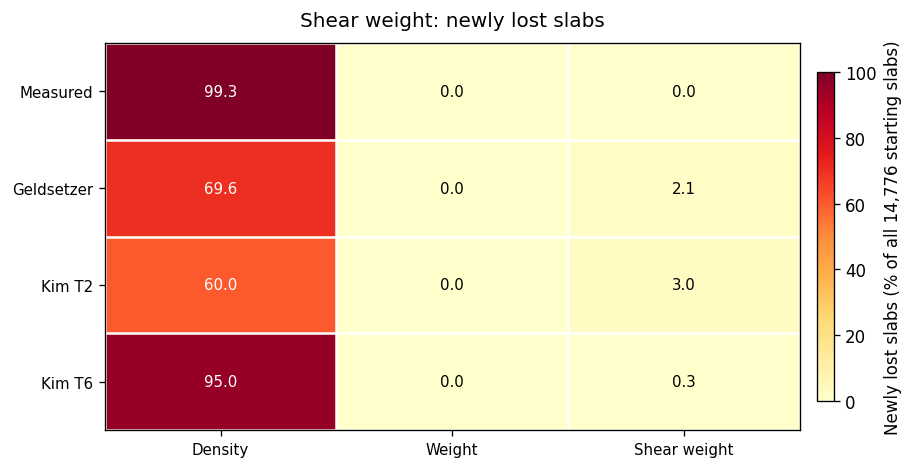

In [59]:
plot_loss_heatmap(weight)
plt.show()

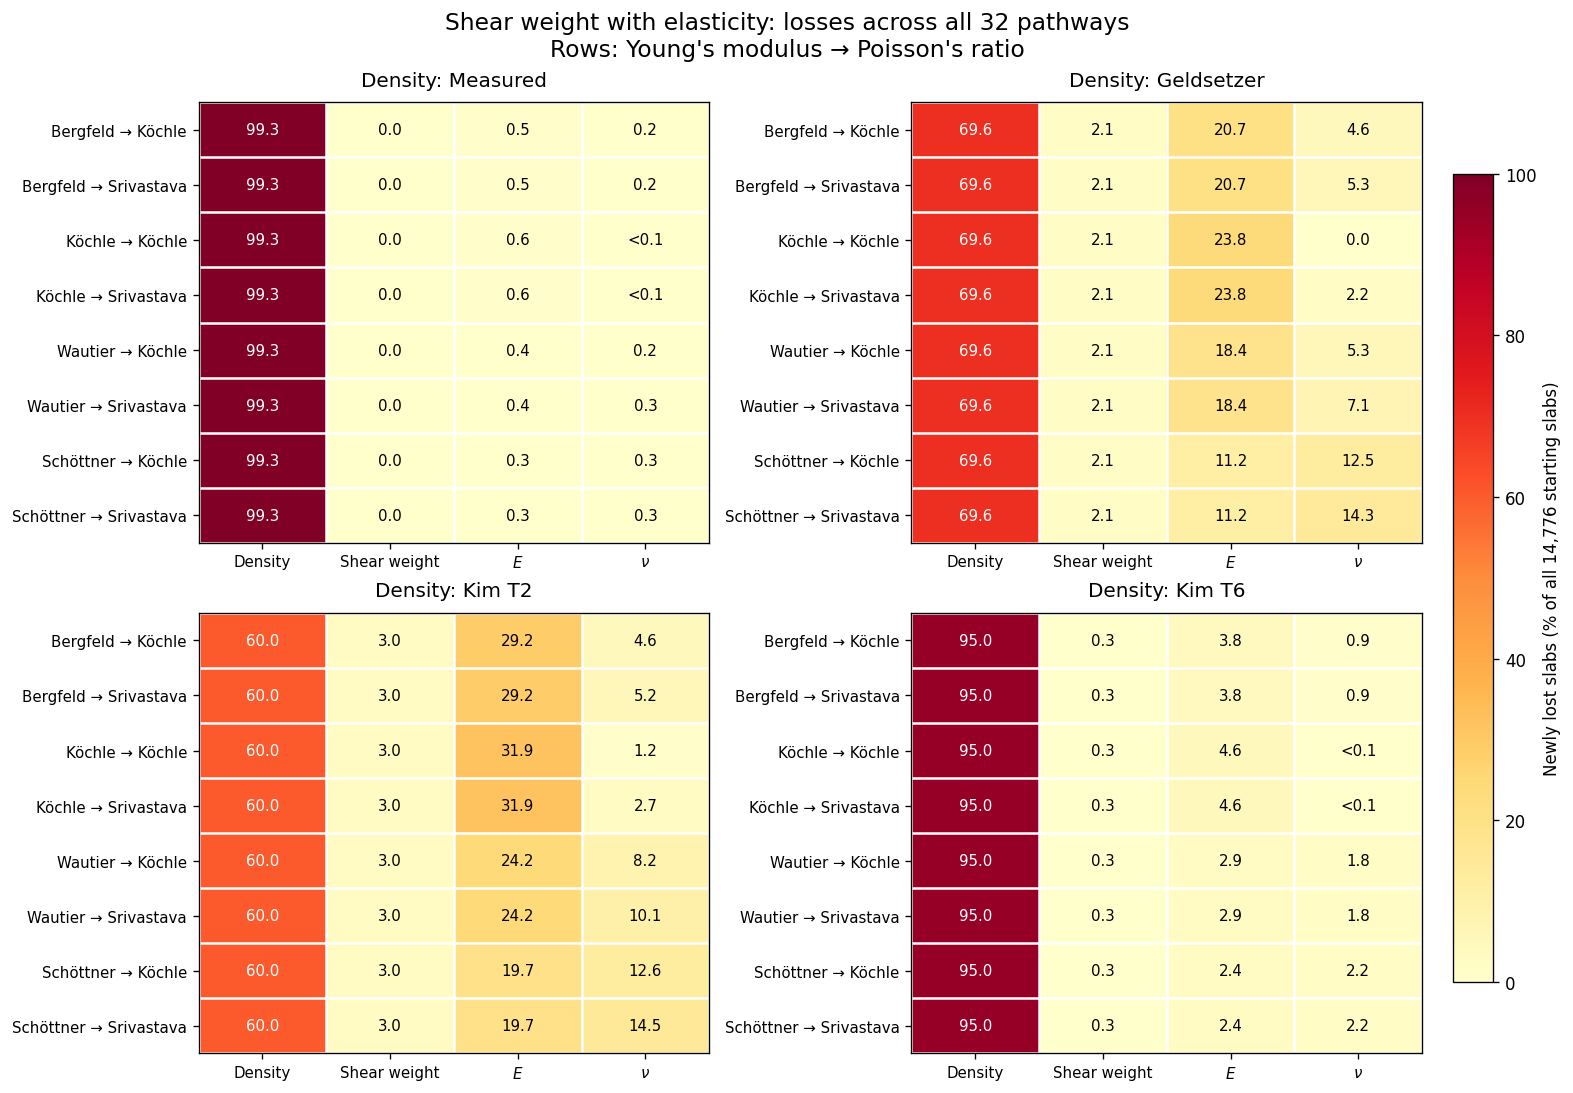

In [60]:
plot_loss_heatmap(elastic_weight)
plt.show()

## 5. Method causes and details

The summary deduplicates affected slabs and layers within each method, upstream context, and cause category. The detail table separates unsupported grain codes, grain-specific hardness bounds, and missing density, hardness, grain form, or grain size. Slope loss is recorded at slab level, so its layer count is zero.

Density details are shared by both targets because the same four density methods act on the same cohort. The density detail view initially shows Kim T2, the highest-coverage method. Change `DENSITY_METHOD` below to inspect Geldsetzer, Kim T6, or direct measurement; use `None` to show all density methods. Uncomment the displays to inspect the tables.


In [61]:
#display(weight.method_summary)
DENSITY_METHOD = "kim_jamieson_table2"  # data_flow, geldsetzer, kim_jamieson_table6, or None
#show_details(weight, "density", DENSITY_METHOD)
#show_details(weight, "slab_weight")
#show_details(weight, "slab_weight_shear")

### Detailed density-method causes

The separate blue and orange panels show missing observations and validity limits for the selected density method. These counts **overlap**: a slab can appear in several bars. Each panel shows its 12 largest detailed causes; `weight.details("density", DENSITY_METHOD)` retains all causes. Grain codes remain separate, and numerical labels include the method's bound. Blocked calculations and other errors remain in the tables.

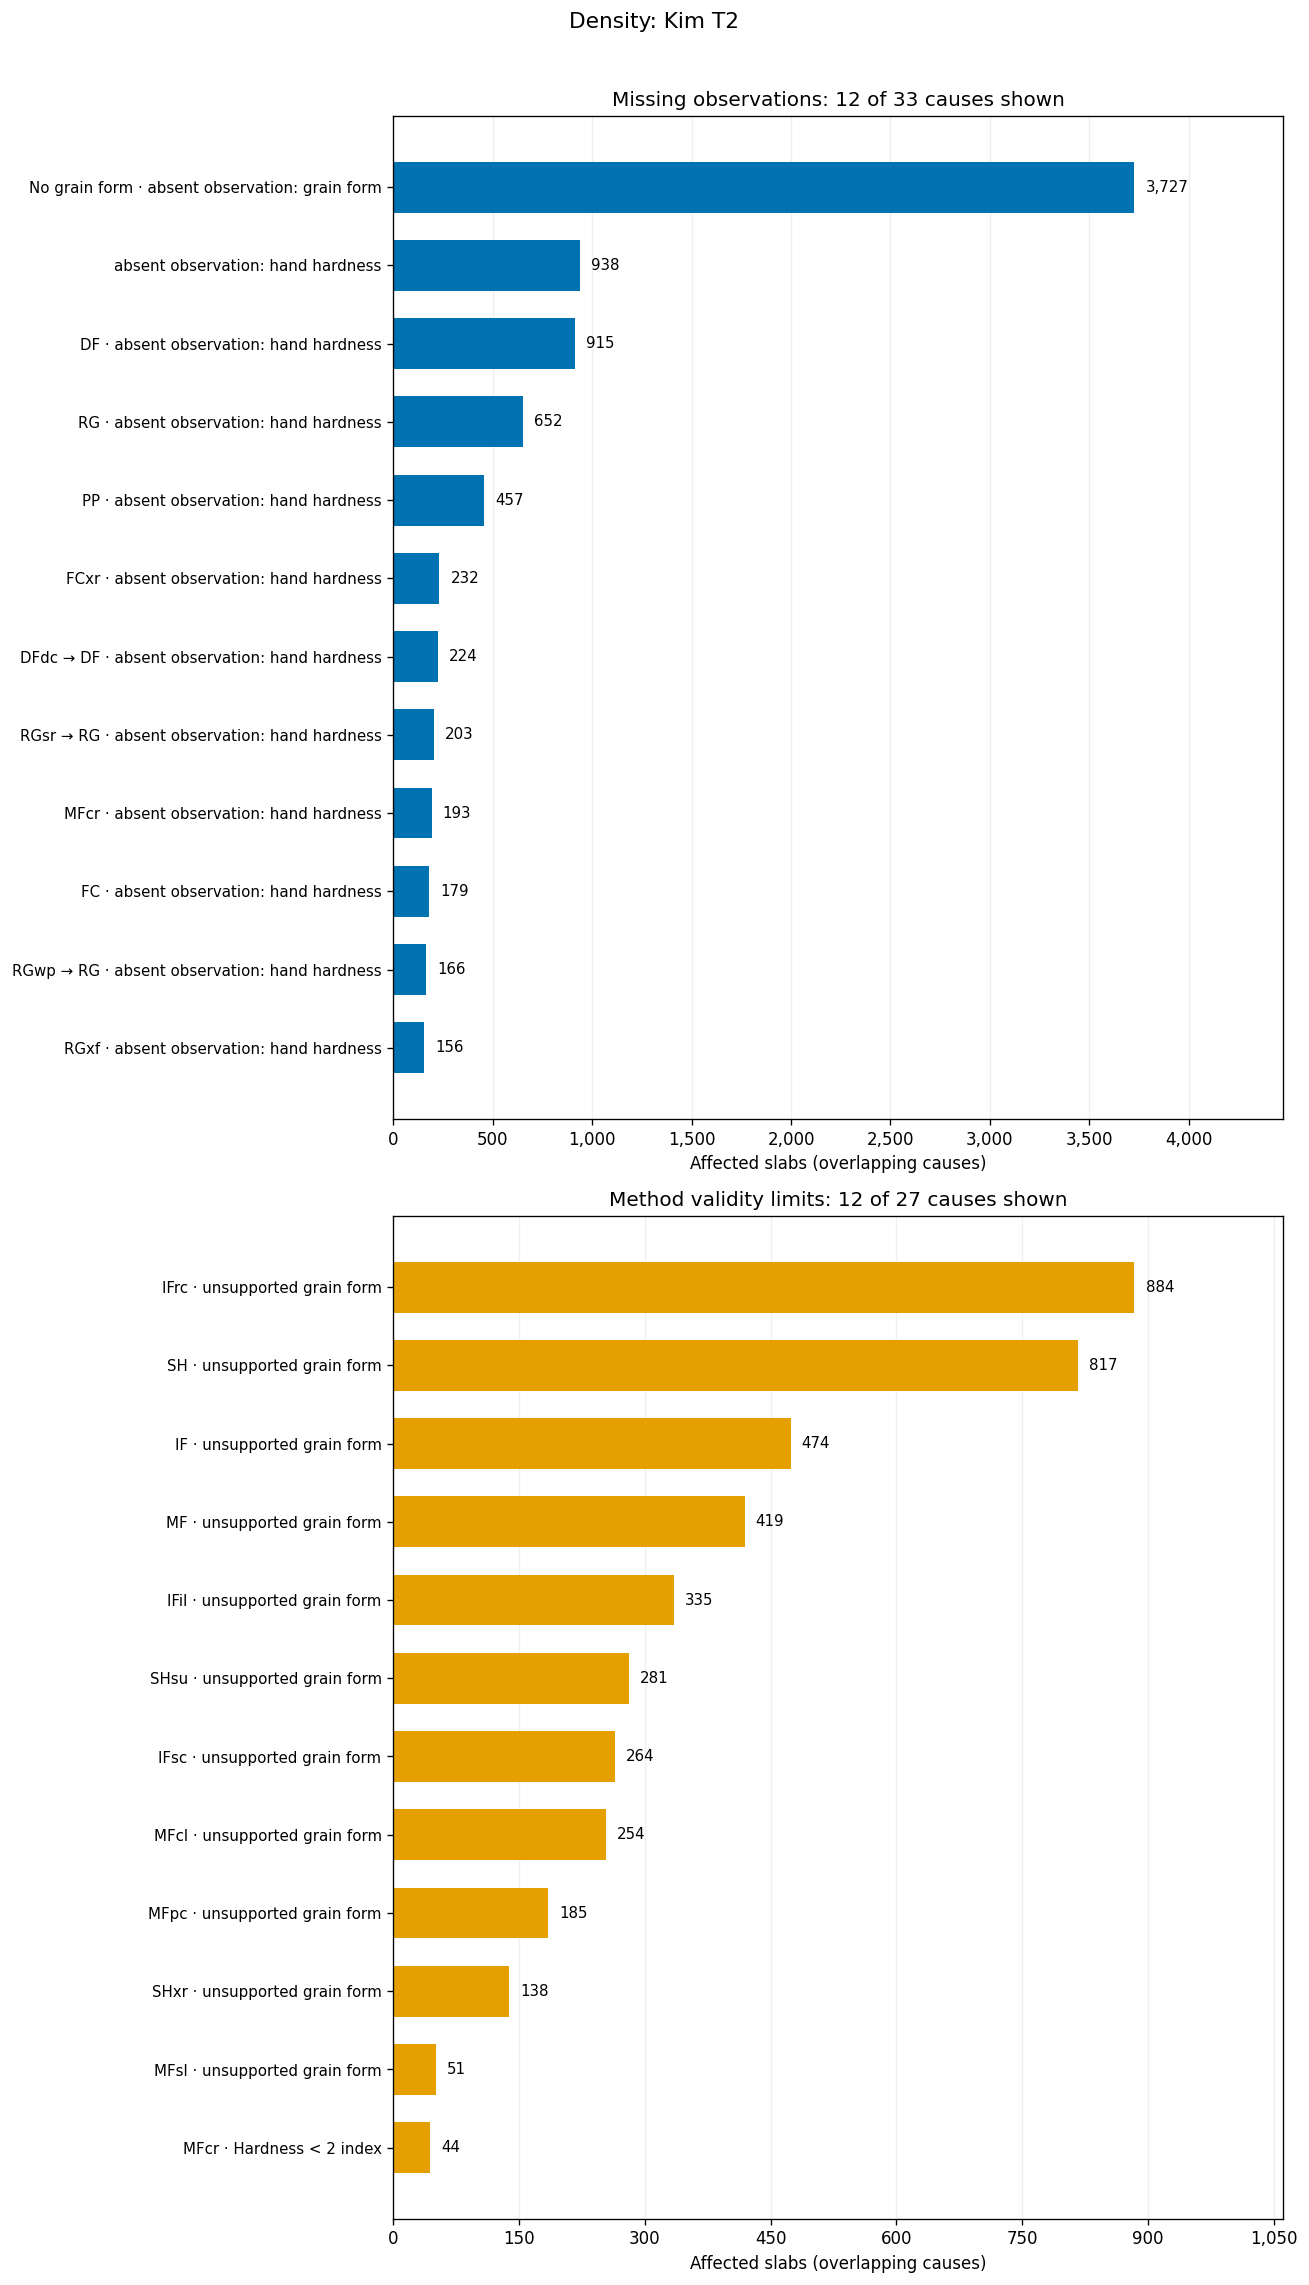

In [62]:
if DENSITY_METHOD is not None:
    plot_method_causes(weight, "density", DENSITY_METHOD, top_n=12)
    plt.show()
else:
    print("Select one DENSITY_METHOD above to display its cause bars.")

### Elasticity-method causes

The elasticity summary includes every method and density context with a recorded cause. Unsupported downstream grain forms remain identifiable even if density could not be calculated; an unavailable density is listed separately as blocked. Uncomment the display below to inspect the summary.


In [63]:
#display(elastic_weight.method_summary)

### Grain form, hardness, and density-range details

Below, choose any E method to inspect its grain-specific failures and the density values outside its validity range. The full table for all E methods is `elastic_weight.details("elastic_modulus")`. Poisson's-ratio details show all methods and density contexts. Uncomment the displays to inspect the tables. The E detail view initially uses Kim T2 density; set `DENSITY_CONTEXT = None` for all density methods.

In [64]:
E_METHOD = "wautier"  # bergfeld, kochle, wautier, or schottner
DENSITY_CONTEXT = "kim_jamieson_table2"  # None for all, or another density method
#show_details(elastic_weight, "elastic_modulus", E_METHOD, DENSITY_CONTEXT)
#show_details(elastic_weight, "poissons_ratio")
#show_details(elastic_weight, "slab_weight")
#show_details(elastic_weight, "slab_weight_shear")
#show_details(elastic_weight, "slab_weight_shear_with_elasticity")

### Detailed elasticity-method causes

The E chart uses `E_METHOD` and `DENSITY_CONTEXT` from the detail view, initially matching the paper's Wautier and Kim T2 pathway. The Poisson's-ratio chart initially shows Köchle. Choose `NU_METHOD = "srivastava"` to inspect its density threshold as well as grain-form constraints, using the selected density context.

Each panel shows the 12 largest overlapping detailed causes. Raw grain subclasses are not combined, and context counts are not added together. The full counts and intervals remain in `elastic_weight.reasons` and the detail tables.

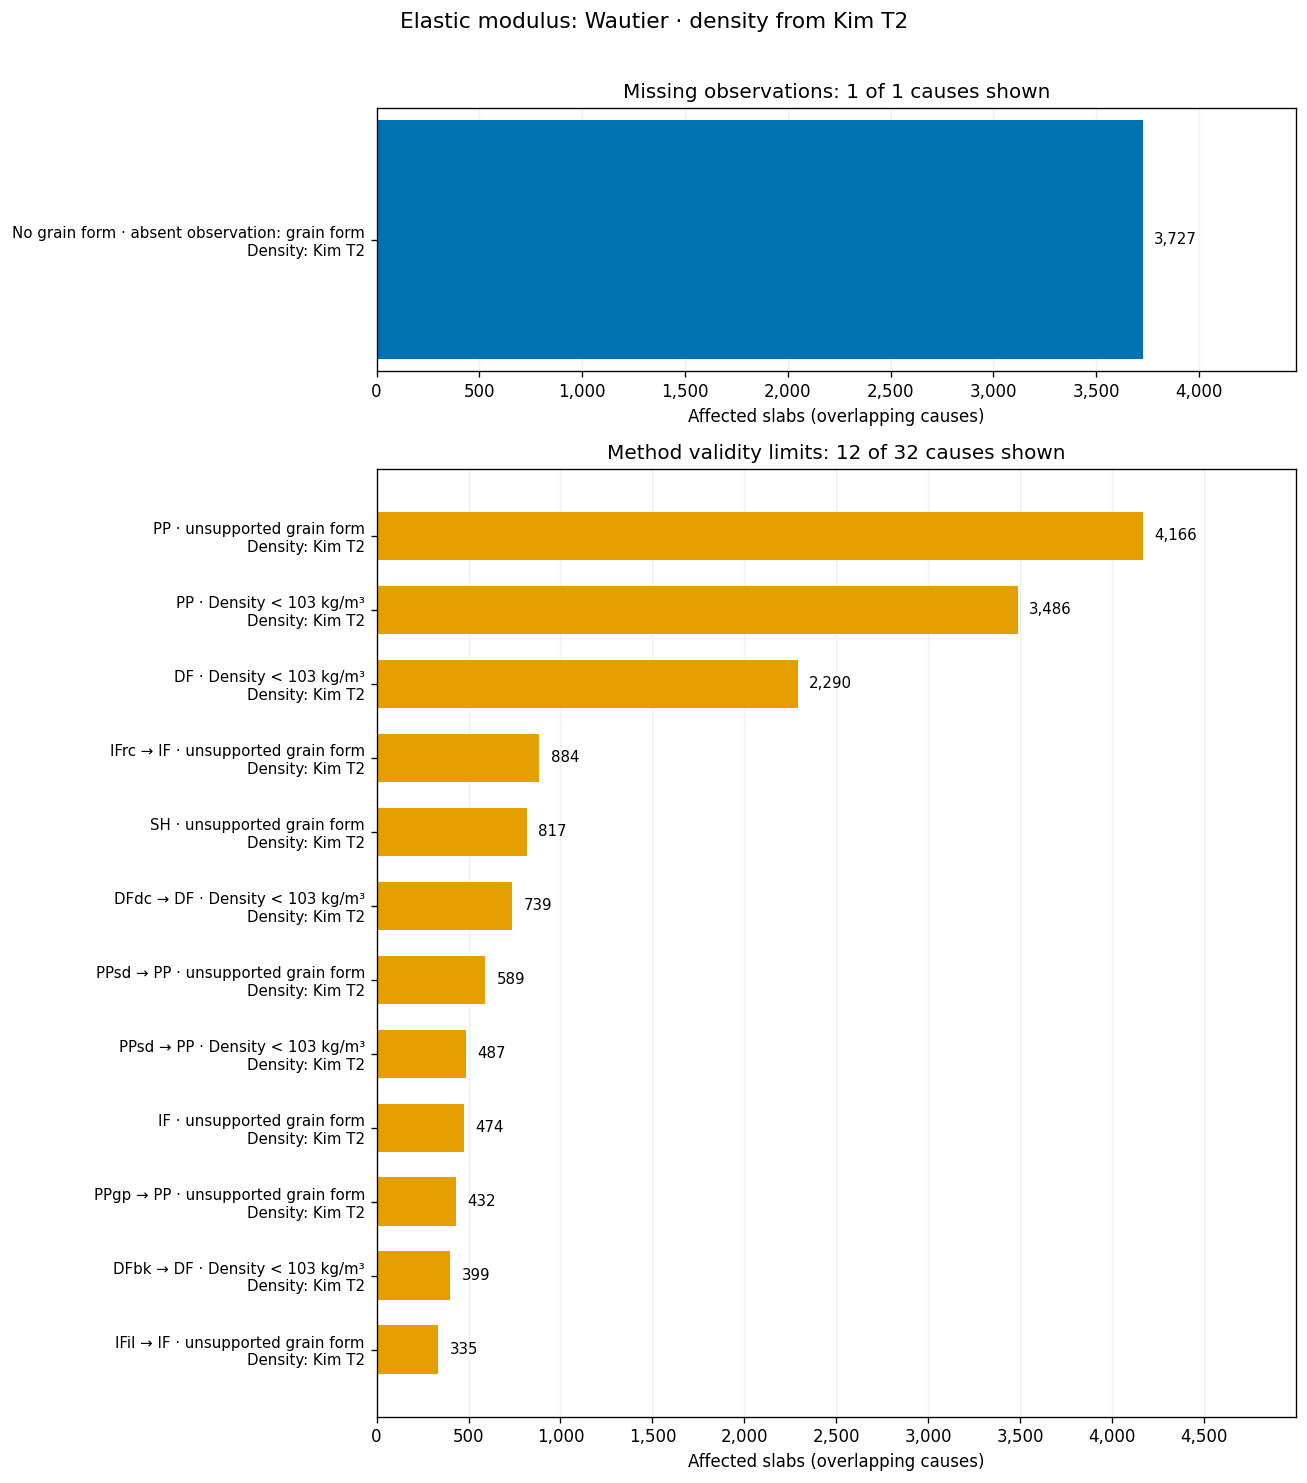

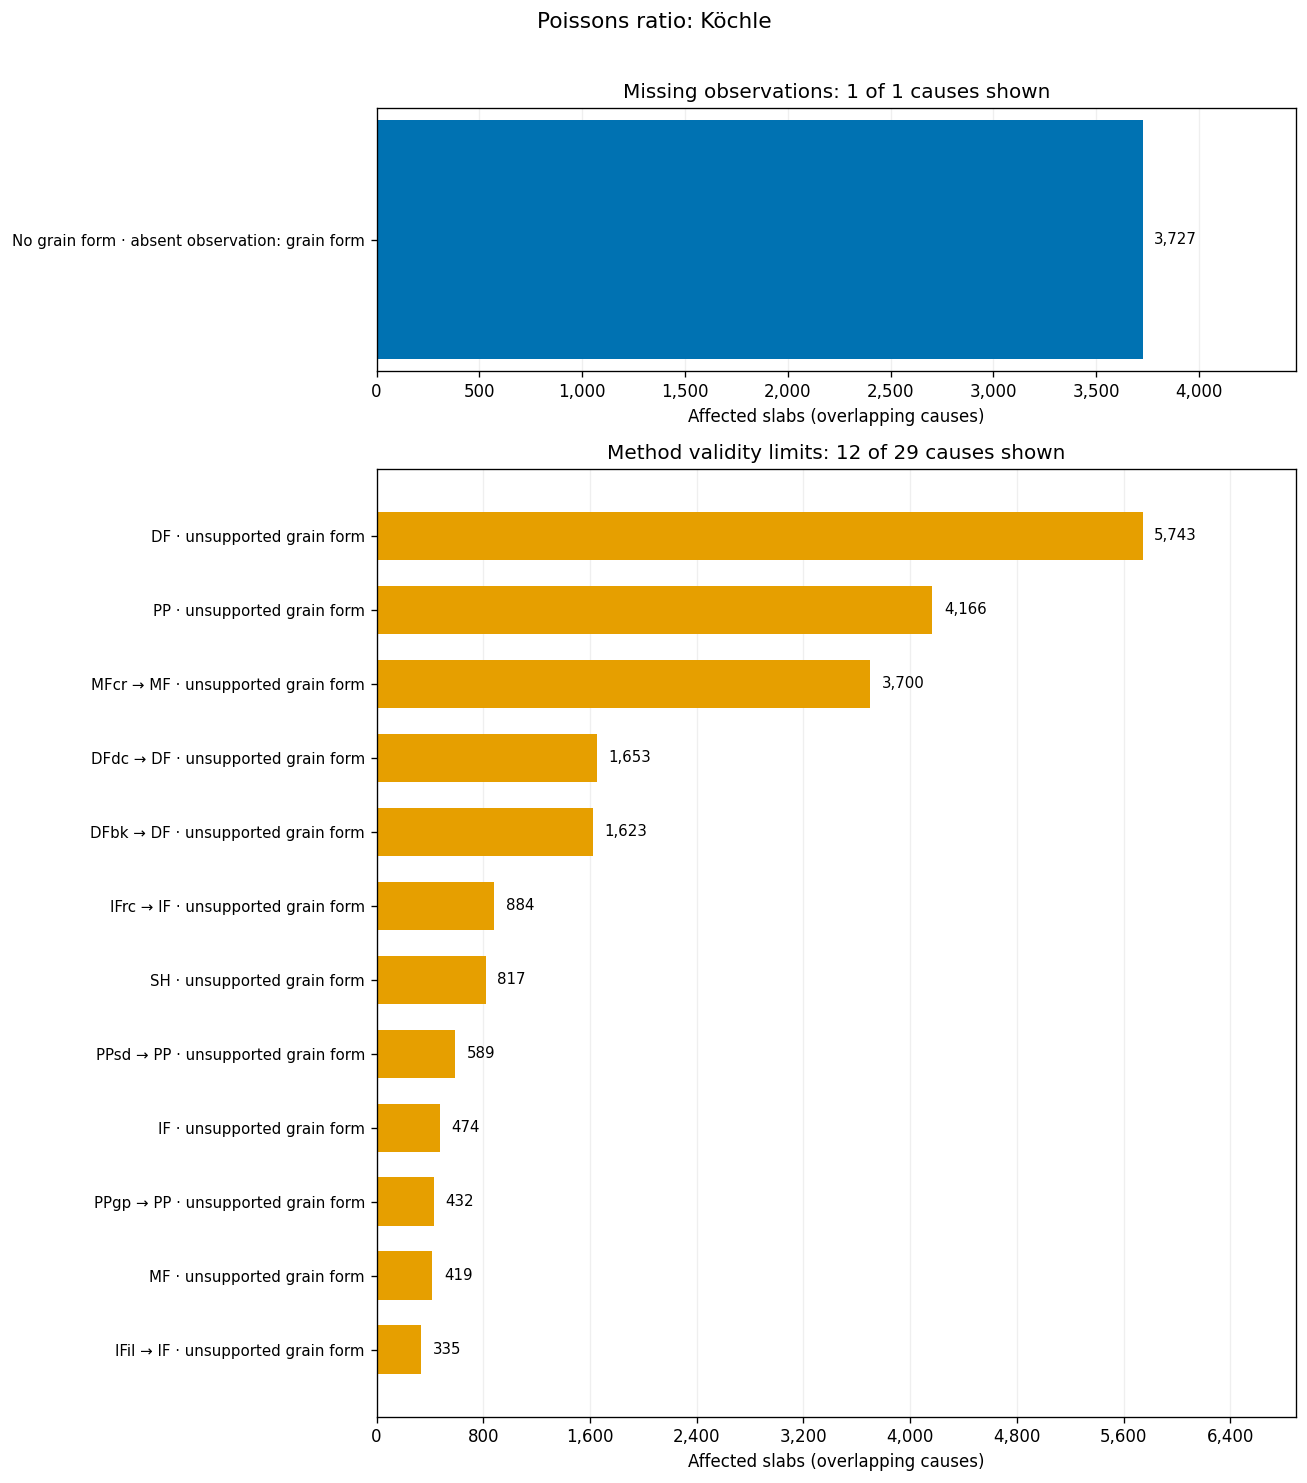

In [65]:
plot_method_causes(elastic_weight, "elastic_modulus", E_METHOD, DENSITY_CONTEXT, top_n=12)
plt.show()

NU_METHOD = "kochle"  # kochle or srivastava
nu_context = DENSITY_CONTEXT if NU_METHOD == "srivastava" else None
plot_method_causes(elastic_weight, "poissons_ratio", NU_METHOD, nu_context, top_n=12)
plt.show()

### Compare bottlenecks

The bottleneck table lists the three largest missing-observation and method-validity counts for each target. These are overlapping affected-slab counts within method contexts, not expected numbers of recoverable slabs. Blocked downstream steps are consequences of upstream loss and are excluded from this ranking. Uncomment the display below to inspect the table.


In [66]:
bottleneck_rows = []
for result in [weight, elastic_weight]:
    for category in ["missing", "validity"]:
        largest = (result.method_summary[result.method_summary.category == category]
                   .sort_values(["slabs", "parameter", "method", "density_context"],
                                ascending=[False, True, True, True]).head(3).copy())
        largest.insert(0, "target", result.target)
        bottleneck_rows.append(largest)
# display(pd.concat(bottleneck_rows, ignore_index=True))